In [ ]:
import os
from google.colab import drive

# Ensure the mount point is clean
if os.path.exists('/content/drive'):
    os.system('umount /content/drive') # Attempt to unmount forcefully if possible
    os.system('rm -rf /content/drive/*') # Remove contents, if any
    os.rmdir('/content/drive') # Remove the directory itself
os.makedirs('/content/drive', exist_ok=True)

drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)

Drive not mounted, so nothing to flush and unmount.
Mounted at /content/drive


Specular Highlight Removal

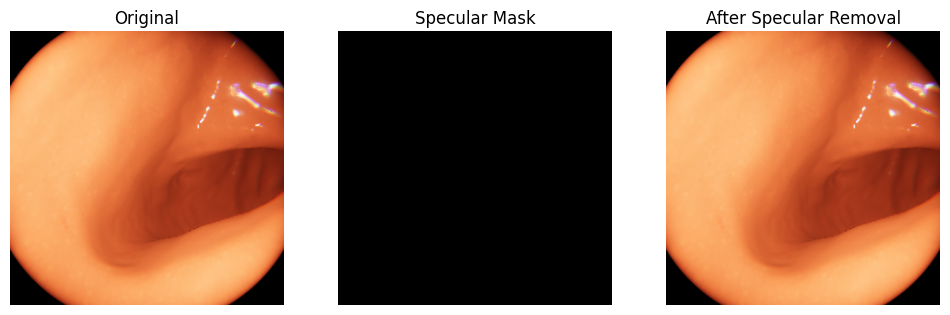

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define the directory containing the frames
FRAME_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/dataset/small_intestine/SampleFrame/specular_removed"

# Load frame (using an example image from the SampleFrame directory)
img_path = f"{FRAME_DIR}/image_0472.png"
img = cv2.imread(img_path)

# Add a check to ensure the image was loaded successfully
if img is None:
    print(f"Error: Could not read image at {img_path}. Please check the path and file.")
else:
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Convert to HSV
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    # Improved specular detection (less strict)
    spec_mask = np.logical_and(v > 210, s < 80).astype(np.uint8) * 255

    # Clean mask with morphology
    kernel = np.ones((5,5), np.uint8)
    spec_mask = cv2.morphologyEx(spec_mask, cv2.MORPH_CLOSE, kernel)
    spec_mask = cv2.morphologyEx(spec_mask, cv2.MORPH_OPEN, kernel)

    # Inpaint highlights
    inpainted = cv2.inpaint(img, spec_mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)
    inpainted_rgb = cv2.cvtColor(inpainted, cv2.COLOR_BGR2RGB)

    # Show results
    plt.figure(figsize=(12,4))
    plt.subplot(1,3,1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(spec_mask, cmap="gray")
    plt.title("Specular Mask")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(inpainted_rgb)
    plt.title("After Specular Removal")
    plt.axis("off")

    plt.show()

In [ ]:
import os
from tqdm import tqdm

IN_DIR  = FRAME_DIR
PRE_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results"

OUT_DIR = f"{PRE_DIR}/specular_removed"
os.makedirs(OUT_DIR, exist_ok=True)

frames = sorted(os.listdir(IN_DIR))

for fname in tqdm(frames):
    in_path  = os.path.join(IN_DIR, fname)
    out_path = os.path.join(OUT_DIR, fname)

    # Skip if already processed (resume-safe)
    if os.path.exists(out_path):
        continue

    img = cv2.imread(in_path)
    if img is None:
        continue

    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)

    # Same thresholds that worked visually
    spec_mask = np.logical_and(v > 210, s < 80).astype(np.uint8) * 255

    # Clean mask
    kernel = np.ones((5,5), np.uint8)
    spec_mask = cv2.morphologyEx(spec_mask, cv2.MORPH_CLOSE, kernel)
    spec_mask = cv2.morphologyEx(spec_mask, cv2.MORPH_OPEN, kernel)

    # Inpaint
    cleaned = cv2.inpaint(img, spec_mask, 3, cv2.INPAINT_TELEA)

    cv2.imwrite(out_path, cleaned)

print("Specular removal completed for all frames.")

100%|██████████| 531/531 [00:28<00:00, 18.77it/s]

Specular removal completed for all frames.


(np.float64(-0.5), np.float64(319.5), np.float64(319.5), np.float64(-0.5))

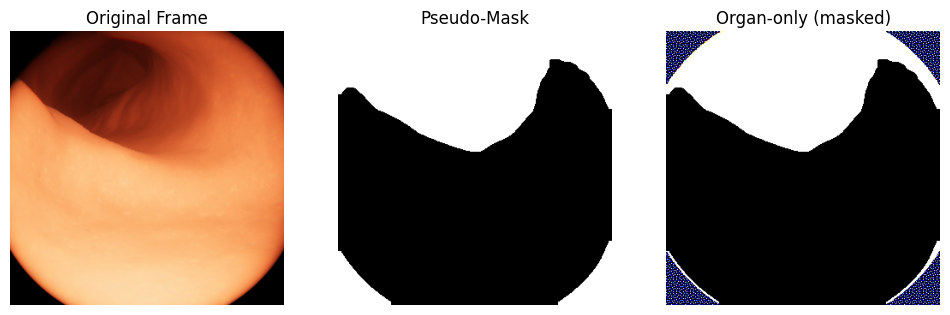

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load one frame
FRAME_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results/specular_removed"
img_path = f"{FRAME_DIR}/image_0031.png"
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Blur to reduce noise
blur = cv2.GaussianBlur(gray, (7, 7), 0)

# Otsu thresholding (automatic)
_, mask = cv2.threshold(
    blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Invert mask (organ usually darker)
mask = cv2.bitwise_not(mask)

# Morphological cleanup
kernel = np.ones((7, 7), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

# Show results
plt.figure(figsize=(12,4))
plt.subplot(1,3,1)
plt.imshow(img_rgb)
plt.title("Original Frame")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(mask, cmap="gray")
plt.title("Pseudo-Mask")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(img_rgb * (mask[..., None] / 255))
plt.title("Organ-only (masked)")
plt.axis("off")


In [ ]:
import os
import cv2
import numpy as np
from tqdm import tqdm

# Output directory for pseudo-masks
MASK_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results/pseudo_masks"
os.makedirs(MASK_DIR, exist_ok=True)

frame_files = sorted(os.listdir(FRAME_DIR))

for fname in tqdm(frame_files):
    img_path = os.path.join(FRAME_DIR, fname)
    img = cv2.imread(img_path)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (7, 7), 0)

    _, mask = cv2.threshold(
        blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    mask = cv2.bitwise_not(mask)

    kernel = np.ones((7, 7), np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

    mask_path = os.path.join(MASK_DIR, fname)
    cv2.imwrite(mask_path, mask)

print("Pseudo-masks generated for all frames.")


100%|██████████| 531/531 [00:18<00:00, 28.95it/s]

Pseudo-masks generated for all frames.


Segmentation


In [ ]:
!pip install segmentation_models_pytorch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 6.5 MB/s eta 0:00:00


In [ ]:

import segmentation_models_pytorch as smp
import torch
import os

# Recreate model architecture
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,   # IMPORTANT: no imagenet now
    in_channels=3,
    classes=1
)

# Define BASE_DIR
BASE_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction"

# Load trained weights
CKPT_DIR = f"{BASE_DIR}/checkpoints"
CKPT_PATH = f"{CKPT_DIR}/unet_segmentation.pth"  # or final name if you renamed

checkpoint = torch.load(CKPT_PATH, map_location="cpu")
model.load_state_dict(checkpoint["model"])

# Move to GPU if available
model = model.cuda() if torch.cuda.is_available() else model
model.eval()

print("Trained U-Net model loaded and ready")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/3D_organ_Reconstruction/checkpoints/unet_segmentation.pth'

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn

import albumentations as A
from albumentations.pytorch import ToTensorV2
import segmentation_models_pytorch as smp

In [ ]:
train_transform = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.RandomBrightnessContrast(p=0.2),
    A.Rotate(limit=10, p=0.3),
    A.Normalize(mean=(0,0,0), std=(1,1,1)),
    ToTensorV2()
])


In [ ]:
class OrganSegDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.images = sorted(os.listdir(image_dir))
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        name = self.images[idx]

        img_path  = os.path.join(self.image_dir, name)
        mask_path = os.path.join(self.mask_dir, name)

        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask = (mask > 0).astype("float32")

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented["image"]
            mask  = augmented["mask"]

        mask = mask.unsqueeze(0)
        return image, mask


In [ ]:
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Create U-Net model
model = smp.Unet(
    encoder_name="resnet34",     # strong & stable encoder
    encoder_weights="imagenet",  # pretrained
    in_channels=3,
    classes=1                    # binary segmentation
)

model.to(device)
model.eval()

print("U-Net model loaded successfully")

Using device: cuda


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/87.3M [00:00<?, ?B/s]

U-Net model loaded successfully


In [ ]:
import torch
import torch.nn as nn

# Loss function for binary segmentation
criterion = nn.BCEWithLogitsLoss()

# Optimizer
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

print("Loss and optimizer initialized")


Loss and optimizer initialized


In [ ]:
FRAME_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results/specular_removed"
MASK_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results/pseudo_masks"

train_dataset = OrganSegDataset(
    FRAME_DIR,
    MASK_DIR,
    transform=train_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True
)

print("Training samples:", len(train_dataset))

Training samples: 531


In [ ]:
BASE_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction"
CKPT_DIR = f"{BASE_DIR}/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

CKPT_PATH = f"{CKPT_DIR}/unet_segmentation.pth"

In [ ]:
start_epoch = 0

if os.path.exists(CKPT_PATH):
    checkpoint = torch.load(CKPT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    start_epoch = checkpoint["epoch"] + 1
    print(f"Resumed from epoch {start_epoch}")
else:
    print("Starting fresh training")

Starting fresh training


In [ ]:
MAX_BATCHES = 200   # 🔴 VERY IMPORTANT (adjustable)
EPOCHS = 15        # logical epochs, not actual runtime epochs

model.train()

for epoch in range(start_epoch, EPOCHS):
    epoch_loss = 0.0

    for batch_idx, (images, masks) in enumerate(train_loader):

        if batch_idx >= MAX_BATCHES:
            break   # 🟢 STOP SAFELY

        images = images.to(device)
        masks  = masks.to(device)

        outputs = model(images)
        loss = criterion(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

    # 🔴 SAVE CHECKPOINT AFTER EACH CHUNK
    torch.save({
        "epoch": epoch,
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict()
    }, CKPT_PATH)

    print(f"Epoch {epoch+1} | Loss: {epoch_loss/(batch_idx+1):.4f} | Saved")

Epoch 1 | Loss: 0.3348 | Saved
Epoch 2 | Loss: 0.1982 | Saved
Epoch 3 | Loss: 0.1591 | Saved
Epoch 4 | Loss: 0.1384 | Saved
Epoch 5 | Loss: 0.1296 | Saved
Epoch 6 | Loss: 0.1133 | Saved
Epoch 7 | Loss: 0.1207 | Saved
Epoch 8 | Loss: 0.1047 | Saved
Epoch 9 | Loss: 0.1047 | Saved
Epoch 10 | Loss: 0.0917 | Saved
Epoch 11 | Loss: 0.0885 | Saved
Epoch 12 | Loss: 0.0881 | Saved
Epoch 13 | Loss: 0.0798 | Saved
Epoch 14 | Loss: 0.0836 | Saved
Epoch 15 | Loss: 0.0763 | Saved


In [ ]:
import os
import cv2
import torch
import numpy as np
from tqdm import tqdm

# Define PRE_DIR (it was defined in cell OuSqft9wVel6 previously)
PRE_DIR = "/content/drive/MyDrive/3D_organ_Reconstruction/results"

# Paths
CLEAN_DIR = f"{PRE_DIR}/specular_removed"
OUT_DIR   = f"{BASE_DIR}/outputs/organ_only_final"
os.makedirs(OUT_DIR, exist_ok=True)

model.eval()

frame_files = sorted(os.listdir(CLEAN_DIR))

for fname in tqdm(frame_files):
    save_path = os.path.join(OUT_DIR, fname)

    # ✅ SKIP IF ALREADY GENERATED
    if os.path.exists(save_path):
        continue

    img_path = os.path.join(CLEAN_DIR, fname)
    img = cv2.imread(img_path)
    if img is None:
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_norm = img_rgb.astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_norm).permute(2,0,1).unsqueeze(0)

    img_tensor = img_tensor.cuda() if torch.cuda.is_available() else img_tensor

    with torch.no_grad():
        pred = torch.sigmoid(model(img_tensor))[0,0].cpu().numpy()

    organ_only = img_rgb * pred[..., None]

    cv2.imwrite(
        save_path,
        cv2.cvtColor(organ_only.astype(np.uint8), cv2.COLOR_RGB2BGR)
    )

print("Organ-only generation completed (or resumed safely).")

100%|██████████| 531/531 [00:20<00:00, 25.75it/s]

Organ-only generation completed (or resumed safely).
